<a href="https://colab.research.google.com/github/appunhitesh/Phone-Pe-Transaction-Case-Study/blob/main/Phone_Transaction_Case_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Phone pe Case** **Study**

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [ ]:
st_us = pd.read_excel('/content/phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752 (2).xlsx',sheet_name = 'State_Txn and Users')
top_5 = st_us.head(5)

#print(st_us.describe())
#print(st_us.dtypes)
#missing value
#st_us[st_us.isna().any(axis=1)]
# Amount Missing value

per_of_amount = st_us['Amount (INR)'].isna().mean()*100
per_of_amount   # 0.19%

np.float64(0.1984126984126984)

In [ ]:
st_tx_s = pd.read_excel('/content/phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752 (2).xlsx',sheet_name = 'State_TxnSplit')
bottom_10 = st_tx_s.tail(10)

#print(st_tx_s.describe())
#print(st_tx_s.dtypes)

st_tx_s[st_tx_s.isna().any(axis=1)]
# No Missing Values

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)


In [ ]:
st_dd = pd.read_excel('/content/phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752 (2).xlsx',sheet_name = 'State_DeviceData')
len(st_dd)
middle_10 = st_dd.iloc[(len(st_dd)//2)-5:(len(st_dd)//2)+5:]

#print(st_dd.describe())
#print(st_dd.dtypes)

st_dd[st_dd.isna().any(axis=1)]
#No Missing Values



,State,Year,Quarter,Brand,Registered Users,Percentage


In [ ]:
dt_u = pd.read_excel('/content/phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752 (2).xlsx',sheet_name = 'District_Txn and Users')
top_bot = pd.concat([dt_u.head(10),dt_u.tail(10)])

#print(dt_u.describe())
#print(dt_u.dtypes)

dt_u[dt_u.isna().any(axis=1)]
#Percentage of missing values by columns
#dt_u['ATV'].isna().mean()*100
# Missing values in ATV and Code

per_of_miss = dt_u['ATV (INR)'].isna().mean()*100  #0.039%

per_of_code = dt_u['Code'].isna().mean()*100      #0.27%



In [ ]:
dd = pd.read_excel('/content/phonepe-pulse_raw-data_q12018-to-q22021-v0-1-5-1720351752 (2).xlsx',sheet_name = 'District Demographics')
every_10 = dd.iloc[10::10]

#print(dd.describe())
#print(dd.dtypes)

dd.isna().sum()
#No missing values

,0
State,0
District,0
Headquarters,0
Population,0
Area (sq km),0
Density,0
Code,0
Alternate Name,0


**Total Number of State and** **District**

In [ ]:
#Total Number of State
Total_state = st_us['State'].nunique()
print(Total_state)

#Total Number of District
Total_district = dt_u['District'].nunique()
print(Total_district)

36
723


**Highest Number of District by State**

In [ ]:
dt_u.groupby(['State'])['District'].nunique().sort_values(ascending = False)

# Highest District in Uttar Pradesh with 75 district

,District
State,
Uttar Pradesh,75
Madhya Pradesh,52
Bihar,38
Tamil Nadu,37
Maharashtra,36
Telangana,33
Gujarat,33
Assam,33
Rajasthan,33


**Transaction Trend Over States**

In [ ]:
TvT = st_us.groupby(['State']).agg(Total_transaction = ('Transactions','sum'),Total_transaction_Amount = ('Amount (INR)','sum'))
TvT



,Total_transaction,Total_transaction_Amount
State,,
Andaman & Nicobar Islands,1223565,3.641818e+09
Andhra Pradesh,1781091169,3.187847e+12
Arunachal Pradesh,8043799,2.225183e+10
Assam,123577981,2.814087e+11
Bihar,713643889,1.639579e+12
Chandigarh,25516542,5.371208e+10
Chhattisgarh,241908549,4.156353e+11
Dadra & Nagar Haveli and Daman & Diu,12462185,1.865878e+10
Delhi,1011031124,1.649942e+12


In [ ]:
# Transaction Volume by States

TvT['Volume'] = TvT['Total_transaction']*TvT['Total_transaction_Amount']
Top_5 = TvT.sort_values(by='Volume',ascending=False).head(5)
print(Top_5)
print("-"*80)
Last_5 = TvT.sort_values(by='Volume',ascending=True).head(5)
print(Last_5)

                Total_transaction  Total_transaction_Amount        Volume
State                                                                    
Karnataka              2981044533              4.361396e+12  1.300152e+22
Maharashtra            2833670154              4.290995e+12  1.215927e+22
Telangana              2347430243              4.574246e+12  1.073772e+22
Andhra Pradesh         1781091169              3.187847e+12  5.677847e+21
Rajasthan              1382918930              2.625584e+12  3.630970e+21
--------------------------------------------------------------------------------
                           Total_transaction  Total_transaction_Amount  \
State                                                                    
Lakshadweep                            71610              1.921587e+08   
Andaman & Nicobar Islands            1223565              3.641818e+09   
Ladakh                               1880109              6.606978e+09   
Mizoram                        

**Most Common Transaction Type in State in Different Quarters**

In [ ]:
top_type = st_tx_s.loc[
    st_tx_s.groupby(["State", "Year", "Quarter"])["Transactions"].idxmax()
]
top_type = (top_type[["State", "Year", "Quarter", "Transaction Type", "Transactions"]]
    .sort_values(["State", "Year", "Quarter"]))
top_type


,State,Year,Quarter,Transaction Type,Transactions
0,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200
5,Andaman & Nicobar Islands,2018,2,Recharge & bill payments,6735
10,Andaman & Nicobar Islands,2018,3,Recharge & bill payments,8636
15,Andaman & Nicobar Islands,2018,4,Recharge & bill payments,11517
20,Andaman & Nicobar Islands,2019,1,Recharge & bill payments,15263
...,...,...,...,...,...
2489,West Bengal,2020,2,Peer-to-peer payments,24855687
2494,West Bengal,2020,3,Peer-to-peer payments,37556349
2499,West Bengal,2020,4,Peer-to-peer payments,46437233
2504,West Bengal,2021,1,Peer-to-peer payments,53869075


**Highest Number of Brand User in Each State**

In [ ]:
Register_user = st_dd.groupby(['State','Brand']).agg(Number_of_User=('Registered Users','sum'))

top_brands = Register_user.loc[Register_user.groupby("State")['Number_of_User'].idxmax()]
top_brands

,,Number_of_User
State,Brand,
Andaman & Nicobar Islands,Xiaomi,97889
Andhra Pradesh,Xiaomi,40061549
Arunachal Pradesh,Xiaomi,437803
Assam,Xiaomi,6979357
Bihar,Xiaomi,33721314
Chandigarh,Xiaomi,896628
Chhattisgarh,Xiaomi,8763373
Dadra & Nagar Haveli and Daman & Diu,Xiaomi,638834
Delhi,Xiaomi,24114984


**Top District by State Based on Population**

In [ ]:
high_pop = dd.loc[dd.groupby(['State','District'])['Population'].idxmax()]

high_pop = high_pop[['State','District','Population']].sort_values(['State','District','Population'],ascending=[True,True,False]).reset_index(drop=True)
high_pop
top_pop_by_state = high_pop.loc[high_pop.groupby('State')['Population'].idxmax()].reset_index(drop=True)
top_pop_by_state

,State,District,Population
0,Andaman & Nicobar Islands,South Andaman,238142
1,Andhra Pradesh,East Godavari,5151549
2,Arunachal Pradesh,Papum Pare,176385
3,Assam,Nagaon,2826006
4,Bihar,Patna,5772804
5,Chandigarh,Chandigarh,1055450
6,Chhattisgarh,Raipur,2160876
7,Dadra & Nagar Haveli and Daman & Diu,Dadra and Nagar Haveli,343709
8,Delhi,North West Delhi,3656539
9,Goa,North Goa,817761


**District Vs Population Chart**

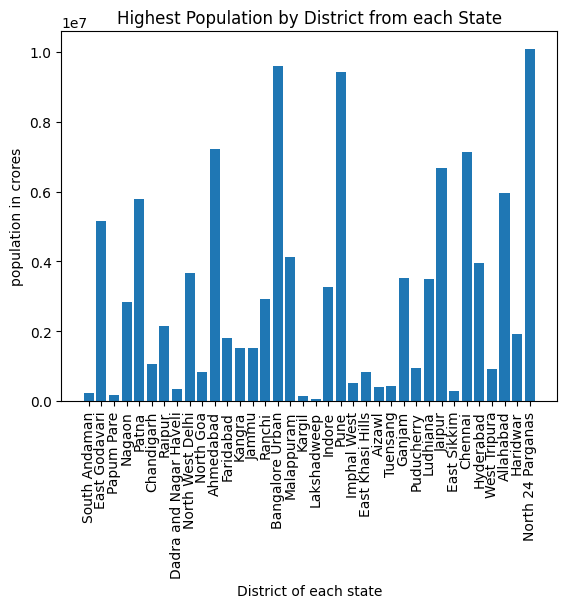

<Figure size 8000x5000 with 0 Axes>

In [ ]:
plt.bar(top_pop_by_state['District'],top_pop_by_state['Population'],label="Population")
plt.title("Highest Population by District from each State")
plt.xlabel('District of each state')
plt.ylabel("population in crores")
plt.xticks(rotation = 90)

plt.figure(figsize=(80,50))
plt.show()

**Average ATV of each State**

In [ ]:
st_us.groupby(['State'])['ATV (INR)'].mean().round(2)

,ATV (INR)
State,
Andaman & Nicobar Islands,3159.27
Andhra Pradesh,1748.09
Arunachal Pradesh,2638.32
Assam,2008.50
Bihar,2023.32
Chandigarh,2113.80
Chhattisgarh,1650.82
Dadra & Nagar Haveli and Daman & Diu,1487.40
Delhi,1589.84


**Highest and Lowest ATV by State**

In [ ]:
Top_ATV = st_us.groupby(['State'])['ATV (INR)'].sum().round(2).sort_values(ascending =False)
print(Top_ATV.head(5))
print(Top_ATV.tail(5))

State
Ladakh                       47715.12
Andaman & Nicobar Islands    44229.73
Mizoram                      40985.25
Lakshadweep                  38865.66
Arunachal Pradesh            36936.54
Name: ATV (INR), dtype: float64
State
Karnataka                               21243.49
Maharashtra                             21229.07
Dadra & Nagar Haveli and Daman & Diu    20823.54
Odisha                                  19993.92
West Bengal                             19230.41
Name: ATV (INR), dtype: float64


**Analysis Of App Usage**

In [ ]:
dt_u.groupby(['State','Year','Quarter'])['App Opens'].sum()

State                      Year  Quarter
Andaman & Nicobar Islands  2018  1                  0
                                 2                  0
                                 3                  0
                                 4                  0
                           2019  1                  0
                                              ...    
West Bengal                2020  2          198589332
                                 3          246554831
                                 4          291721919
                           2021  1          316832674
                                 2          275341466
Name: App Opens, Length: 504, dtype: int64

**Trend in App Usage**

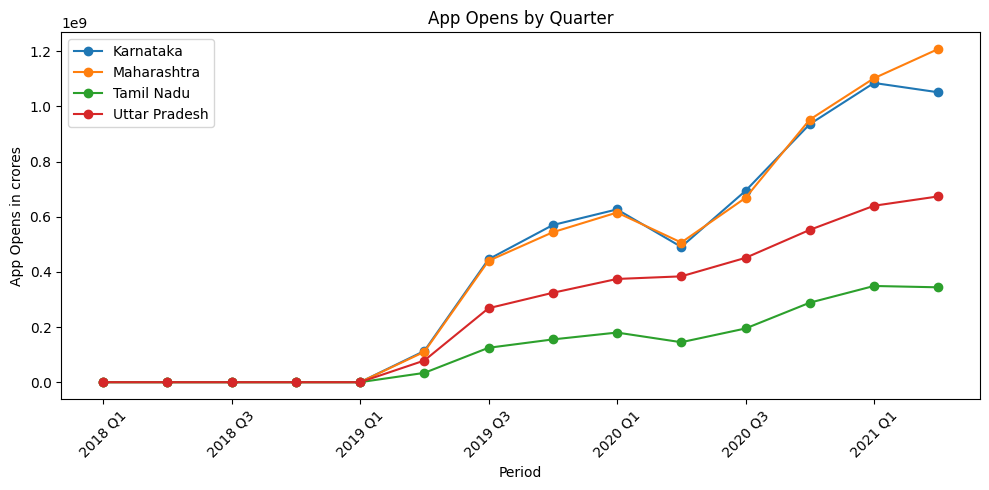

In [ ]:
# Grouping by Year and Quarter for each State
app_opens = dt_u.groupby(['State','Year','Quarter'])['App Opens'].sum().reset_index()

# Creating Period Column
app_opens['Period'] = app_opens['Year'].astype(str) + ' Q' + app_opens['Quarter'].astype(str)


# Pick 4 states
states = ['Maharashtra', 'Karnataka', 'Tamil Nadu', 'Uttar Pradesh']
subset = app_opens[app_opens['State'].isin(states)]

# Pivot: one column per state
pivot = subset.pivot(index='Period', columns='State', values='App Opens')

# Plot
pivot.plot(kind='line', marker='o', figsize=(10, 5))
plt.legend()
plt.title('App Opens by Quarter')
plt.ylabel('App Opens in crores')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Distribution of Transaction Type in Chart**

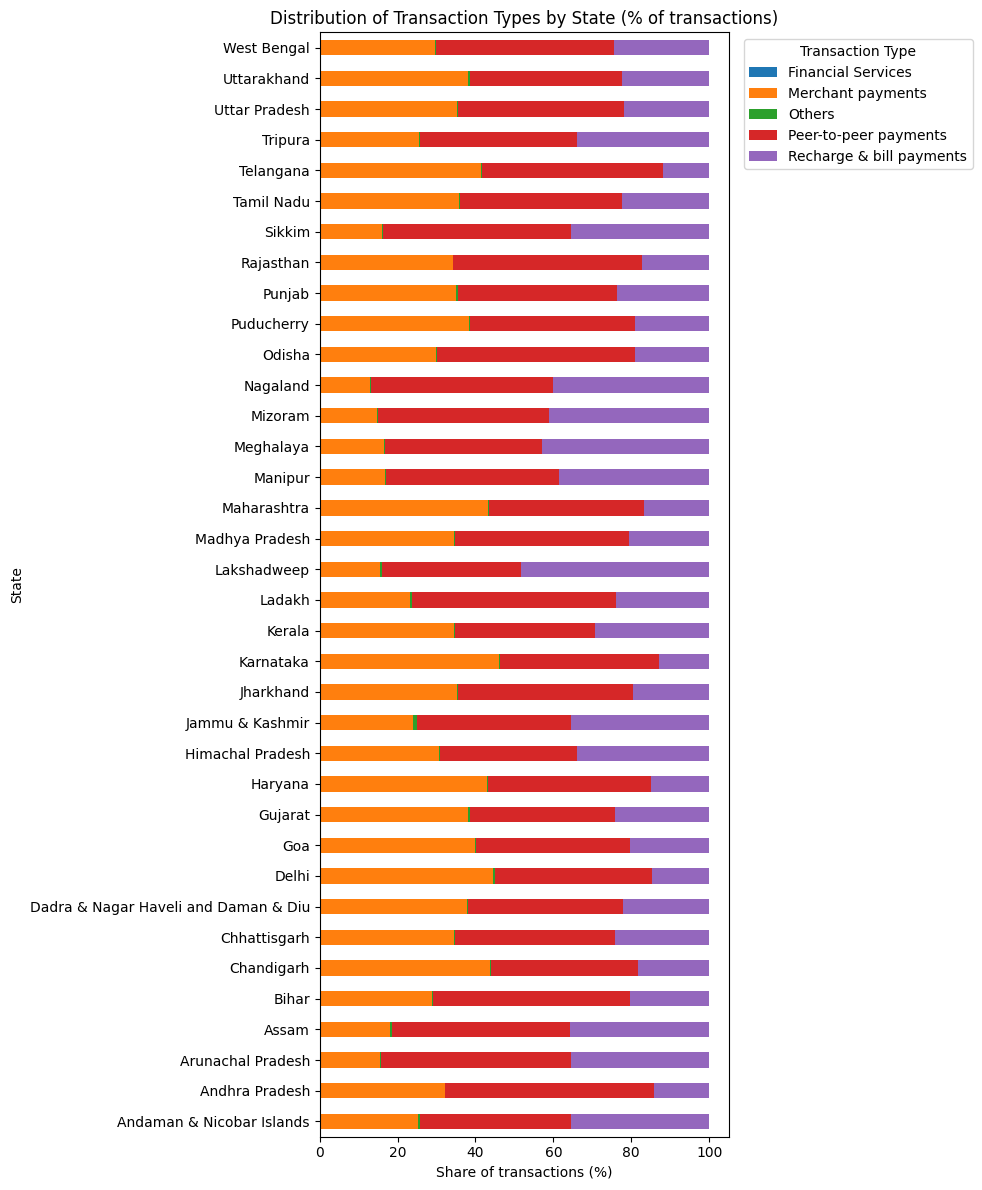

In [ ]:
#Finding latest year
max_year = st_tx_s['Year'].max()
#Finding latest quarter
max_quarter = st_tx_s.loc[st_tx_s['Year']==max_year,'Quarter'].max()
max_quarter
# Filtering only latest quarter
data = st_tx_s[(st_tx_s['Year']==max_year) & (st_tx_s['Quarter']==max_quarter)]

graph_data = data.pivot_table(index ='State',columns='Transaction Type',values = 'Transactions',aggfunc = 'sum')

# % calculation of each transaction type
pivot_pct = graph_data.div(graph_data.sum(axis=1), axis=0) * 100

#stacked horizontal bars
pivot_pct.plot(kind="barh", stacked=True, figsize=(10, 12))

plt.title("Distribution of Transaction Types by State (% of transactions)")
plt.xlabel("Share of transactions (%)")
plt.legend(title="Transaction Type", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()



**Unique Mapping**

In [ ]:
dt_u.groupby(['State','District'])['Code'].nunique().count()

dt_u.groupby(['Code'])['District'].nunique().count()

# Dropping null values
dt_u.dropna(subset=['Code'],inplace=True)

#Mapping into Dictionary
mapping = dict(zip(dt_u['District'],dt_u['Code']))


#Exporting into file
df = pd.DataFrame(list(mapping.items()),columns= ['District','Code'])
df.to_csv('district_code.csv',index=False)


**Data Quality Checks**

In [ ]:
#State Level Data
state_data = st_us.groupby(['State']).agg(Total_Transaction=('Transactions','sum'),Total_Transaction_value=('Amount (INR)','sum'),Total_Registered_user=('Registered Users','sum'))

district_data = dt_u.groupby(['State']).agg(TT=('Transactions','sum'),TTV=('Amount (INR)','sum'),TRU = ('Registered Users','sum'))
district_data

merged = pd.merge(state_data,district_data,left_on='State',right_on='State',how = 'inner')
# where there is mismatch
merged[(merged['Total_Transaction']) != (merged['TT'])]


# There is a mismatch in Jammu and Kashmir data


,Total_Transaction,Total_Transaction_value,Total_Registered_user,TT,TTV,TRU
State,,,,,,
Jammu & Kashmir,45053328,1.094954e+11,9756438,44915603,1.089977e+11,9714192


**Ratio of User by Population**

In [ ]:
user_to_pop = pd.merge(st_us,dd,left_on='State',right_on='State',how ='inner')
new_data = user_to_pop.groupby(['State']).agg(Registered_User=('Registered Users','sum'),Population=('Population','sum')).reset_index()

new_data['ratio']= new_data['Registered_User']/new_data['Population']

new_data

,State,Registered_User,Population,ratio
0,Andaman & Nicobar Islands,1225188,5328134,0.229947
1,Andhra Pradesh,2054103441,691302864,2.971351
2,Arunachal Pradesh,46555350,22484658,2.070538
3,Assam,913265534,482459390,1.892938
4,Bihar,4380820880,1453451314,3.014082
5,Chandigarh,3801466,14776300,0.257268
6,Chhattisgarh,1048554864,362151412,2.895349
7,Dadra & Nagar Haveli and Daman & Diu,8103336,8217384,0.986121
8,Delhi,1049121194,235031174,4.463753
9,Goa,9510640,20408122,0.466022


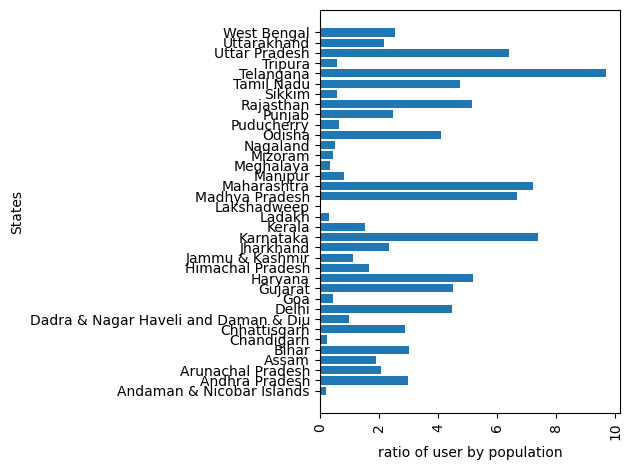

In [ ]:
plt.barh(new_data['State'],new_data['ratio'],label='User_pop_ratio')
plt.xticks(rotation=90)

plt.xlabel('ratio of user by population')
plt.ylabel('States')
plt.tight_layout()
plt.show()

**Correlation between Population Density and Transaction Volume**

In [ ]:
# grouping by code in dt_u and calculating total transaction by code
tx = (dt_u.groupby("Code")["Transactions"].sum()).reset_index()

# merging code from dt_u with dd and retrive required details
pop_den = tx.merge(dd[["Code", "State", "District", "Population", "Density"]],
                  on="Code", how="inner")

# Correlation between Population Density and Transaction
correlation_data = pop_den['Density'].corr(pop_den['Transactions'])
print(correlation_data.round(2))



0.25


**Scatter Plot chart**

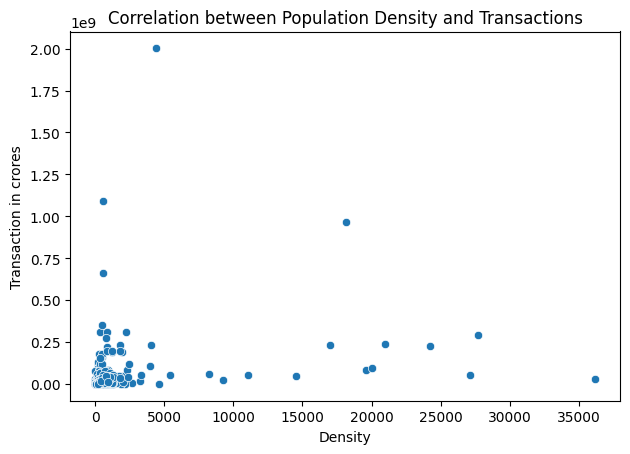

In [ ]:
sns.scatterplot(pop_den,x=pop_den['Density'],y=pop_den['Transactions'])
plt.title('Correlation between Population Density and Transactions')
plt.tight_layout()
plt.ylabel('Transaction in crores')
plt.show()

**Average Transaction Amount Per User**

In [ ]:
merged = st_tx_s.merge(st_us[['State','Year','Quarter','Registered Users']],on = ['State','Year','Quarter'],how ='left')
data = merged.groupby(['State'])['Transactions'].sum()
data1 = merged.groupby(['State'])['Registered Users'].sum()
avg_user = pd.concat([data,data1],axis=1).reset_index()
avg_user['Average_Transaction_Per_User'] = avg_user['Transactions']/avg_user['Registered Users']
avg_user


,State,Transactions,Registered Users,Average_Transaction_Per_User
0,Andaman & Nicobar Islands,1223565,2041980,0.599205
1,Andhra Pradesh,1781091169,790039785,2.254432
2,Arunachal Pradesh,8043799,9311070,0.863896
3,Assam,123577981,134303755,0.920138
4,Bihar,713643889,576423800,1.238054
5,Chandigarh,25516542,19007330,1.342458
6,Chhattisgarh,241908549,187241940,1.291957
7,Dadra & Nagar Haveli and Daman & Diu,12462185,13505560,0.922745
8,Delhi,1011031124,476873270,2.120125
9,Goa,24481604,23776600,1.029651


**Top 5 and Last 5 Average User per State**

In [ ]:
avg_user.sort_values(by='Average_Transaction_Per_User',ascending=False).head(5)

,State,Transactions,Registered Users,Average_Transaction_Per_User
31,Telangana,2347430243,746121070,3.146179
15,Karnataka,2981044533,1015492820,2.935564
1,Andhra Pradesh,1781091169,790039785,2.254432
8,Delhi,1011031124,476873270,2.120125
28,Rajasthan,1382918930,748850320,1.846723


In [ ]:
avg_user.sort_values(by='Average_Transaction_Per_User',ascending=False).tail(5)

,State,Transactions,Registered Users,Average_Transaction_Per_User
23,Mizoram,2162776,3028060,0.714245
32,Tripura,12018152,18307875,0.656447
17,Ladakh,1880109,2899125,0.648509
0,Andaman & Nicobar Islands,1223565,2041980,0.599205
18,Lakshadweep,71610,161644,0.443011


**Ratio of each brand user to total Registered User by State**

In [ ]:
ratio_data = st_dd.merge(
    st_us[["State", "Year", "Quarter", "Registered Users"]],
    on=["State", "Year", "Quarter"],
    how="left",
    suffixes=("_brand", "_total")
)
ratio_data['ratio'] = ratio_data['Registered Users_brand']/ratio_data['Registered Users_total']
print(ratio_data['ratio'])
pivot = ratio_data.pivot_table(index='State',columns='Brand',values='ratio').fillna(0)
pivot_pct = round(pivot.iloc[:,:]*100,2)
pivot_pct

0       0.247033
1       0.214392
2       0.145697
3       0.074332
4       0.049258
          ...   
5539    0.019513
5540    0.016551
5541    0.015182
5542    0.011201
5543    0.107267
Name: ratio, Length: 5544, dtype: float64


Brand,Apple,Asus,COOLPAD,Gionee,HMD Global,Huawei,Infinix,Lava,Lenovo,Lyf,Micromax,Motorola,OnePlus,Oppo,Others,Realme,Samsung,Tecno,Vivo,Xiaomi
State,,,,,,,,,,,,,,,,,,,,
Andaman & Nicobar Islands,2.57,0.00,0.0,0.00,0.00,2.79,0.00,0.00,2.10,0.0,0.00,2.64,4.16,8.60,8.64,5.24,19.21,1.47,19.99,24.15
Andhra Pradesh,2.77,0.00,0.0,0.00,0.00,2.54,0.00,0.00,1.91,0.0,0.00,3.31,2.63,10.30,7.72,7.42,20.18,0.00,15.85,25.37
Arunachal Pradesh,2.21,0.00,0.0,1.61,0.00,1.13,0.00,0.00,1.61,0.0,0.00,1.26,1.27,14.47,7.28,6.37,19.95,0.00,20.43,23.88
Assam,1.62,1.62,0.0,1.71,0.00,1.71,0.00,0.00,1.66,0.0,0.00,1.75,0.00,12.70,11.71,7.60,15.53,0.00,17.79,26.24
Bihar,1.15,0.00,0.0,0.00,0.82,1.61,1.15,0.00,1.61,0.0,1.23,2.01,0.00,11.50,9.77,8.18,20.50,0.97,13.34,29.20
Chandigarh,8.22,0.00,0.0,0.00,1.11,1.51,0.00,0.00,1.70,0.0,1.75,2.57,3.16,11.71,9.12,3.48,19.93,0.00,14.99,23.77
Chhattisgarh,1.68,0.00,0.0,0.00,0.00,0.74,0.00,0.00,1.25,0.0,8.27,1.26,1.59,10.51,8.47,6.43,17.38,0.00,19.61,23.61
Dadra & Nagar Haveli and Daman & Diu,2.06,0.00,0.0,0.00,0.00,1.65,0.00,0.00,2.09,0.0,1.59,2.06,1.43,11.64,9.86,6.27,17.83,1.20,21.21,23.94
Delhi,5.78,0.00,0.0,0.00,0.00,1.79,0.00,0.00,1.79,0.0,0.00,3.11,3.11,11.07,9.75,4.30,19.09,0.00,14.78,25.44


**Device Usage chart for each State**

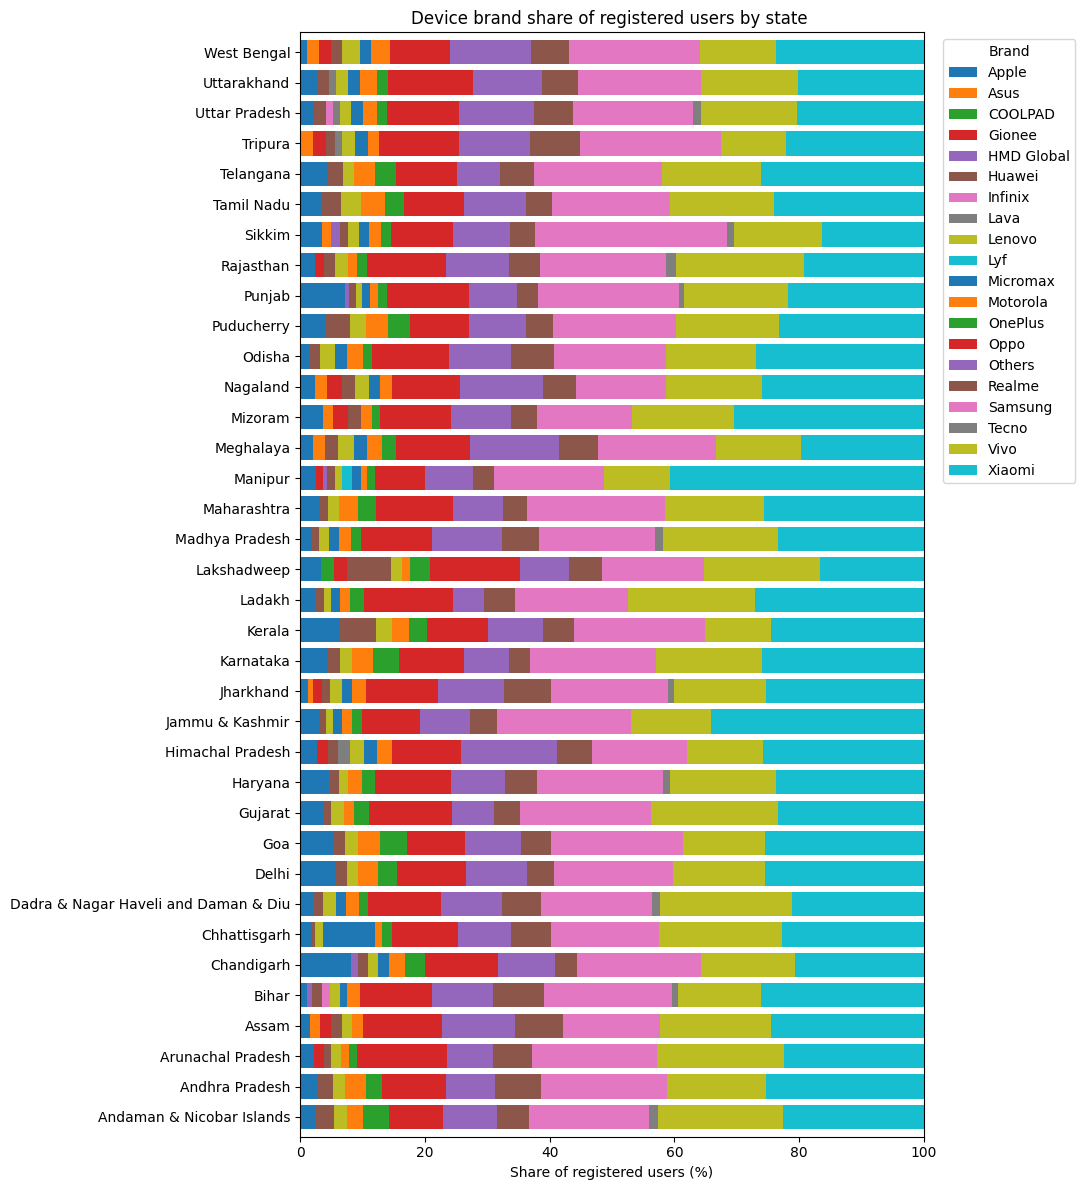

In [ ]:
ax = pivot_pct.plot(kind="barh", stacked=True, figsize=(11, 12), width=0.8)
ax.set_title("Device brand share of registered users by state ")
ax.set_xlabel("Share of registered users (%)")
ax.set_ylabel("")
ax.set_xlim(0, 100)
ax.legend(title="Brand", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# **Data Visualization**

**Total Transaction and amount over time**

                         State  Year  Quarter  Transactions  Amount (INR)  \
0    Andaman & Nicobar Islands  2018        1          6658  1.463176e+07   
1    Andaman & Nicobar Islands  2018        2         11340  2.833854e+07   
2    Andaman & Nicobar Islands  2018        3         16265  5.555747e+07   
3    Andaman & Nicobar Islands  2018        4         23758  9.054834e+07   
4    Andaman & Nicobar Islands  2019        1         30486  1.022997e+08   
..                         ...   ...      ...           ...           ...   
499                West Bengal  2020        2      57676797  1.000994e+11   
500                West Bengal  2020        3      79954504  1.568134e+11   
501                West Bengal  2020        4     100340645  1.991655e+11   
502                West Bengal  2021        1     118254052  2.429372e+11   
503                West Bengal  2021        2     141897437  2.794348e+11   

      Period  
0    2018 Q1  
1    2018 Q2  
2    2018 Q3  
3    2018 Q4  


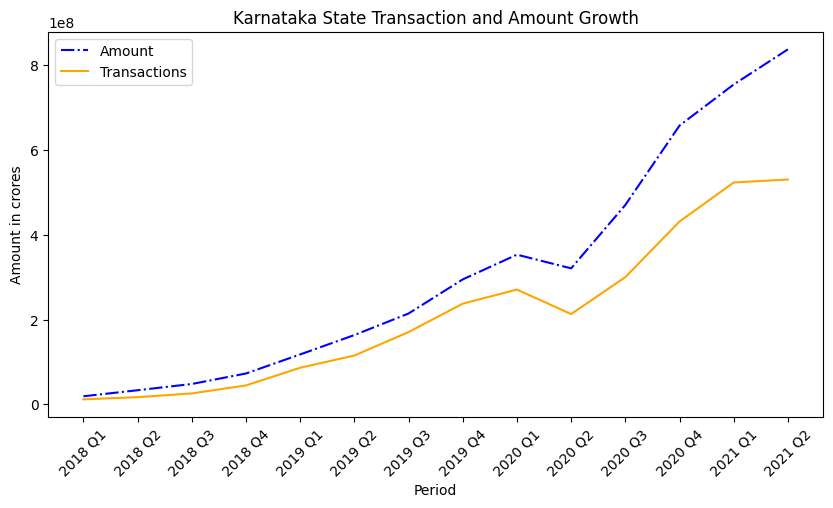

In [ ]:
from matplotlib.lines import lineStyles
# Pick any states
state = ['Karnataka']
# Group by State,Year,Quarter and sum all transactions and amount
trend = st_us.groupby(['State','Year','Quarter'])[['Transactions','Amount (INR)']].sum().reset_index()
# create period for chart
trend['Period'] = trend['Year'].astype(str)+ ' Q'+trend['Quarter'].astype(str)
sub_trend = trend[trend['State'].isin(state)]

plt.figure(figsize=(10,5))
plt.plot(sub_trend['Period'],sub_trend['Amount (INR)']/1e3,label='Amount',linestyle='dashdot',color='blue')
plt.plot(sub_trend['Period'],sub_trend['Transactions'],label='Transactions',linestyle='solid',color= 'orange')
plt.title("Karnataka State Transaction and Amount Growth")
plt.xticks(rotation=45)
plt.xlabel('Period')
plt.ylabel('Amount in crores')

plt.legend()
plt.show()



**Pie chart for Transaction Types for Specific State ,Year and Quarter**

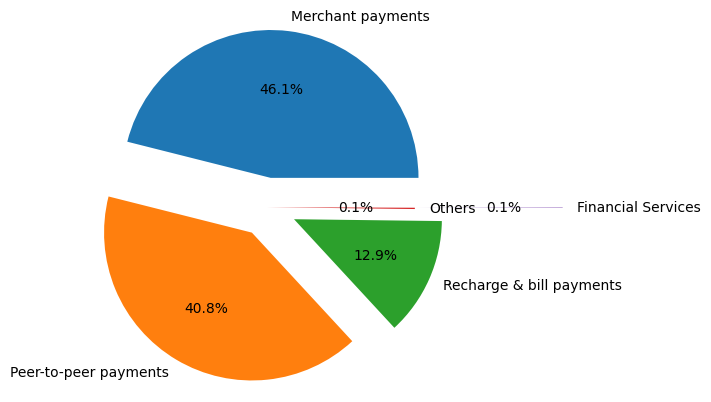

,Transactions
Transaction Type,
Merchant payments,244460862
Peer-to-peer payments,216539959
Recharge & bill payments,68599238
Others,744208
Financial Services,304779


In [ ]:
state , year ,quarter = 'Karnataka',2021,2
data = st_tx_s[(st_tx_s['State'] == state) & (st_tx_s['Year']==year) & (st_tx_s['Quarter']==quarter)]

data_new = data.sort_values(by='Transactions',ascending=False)
pie_data = data_new.set_index('Transaction Type')['Transactions']

plt.pie(pie_data,labels=pie_data.index,autopct='%1.1f%%',explode=(0.2,0.2,0.2,0.,1))
plt.show()

pie_data

**Population Density of District in a State**

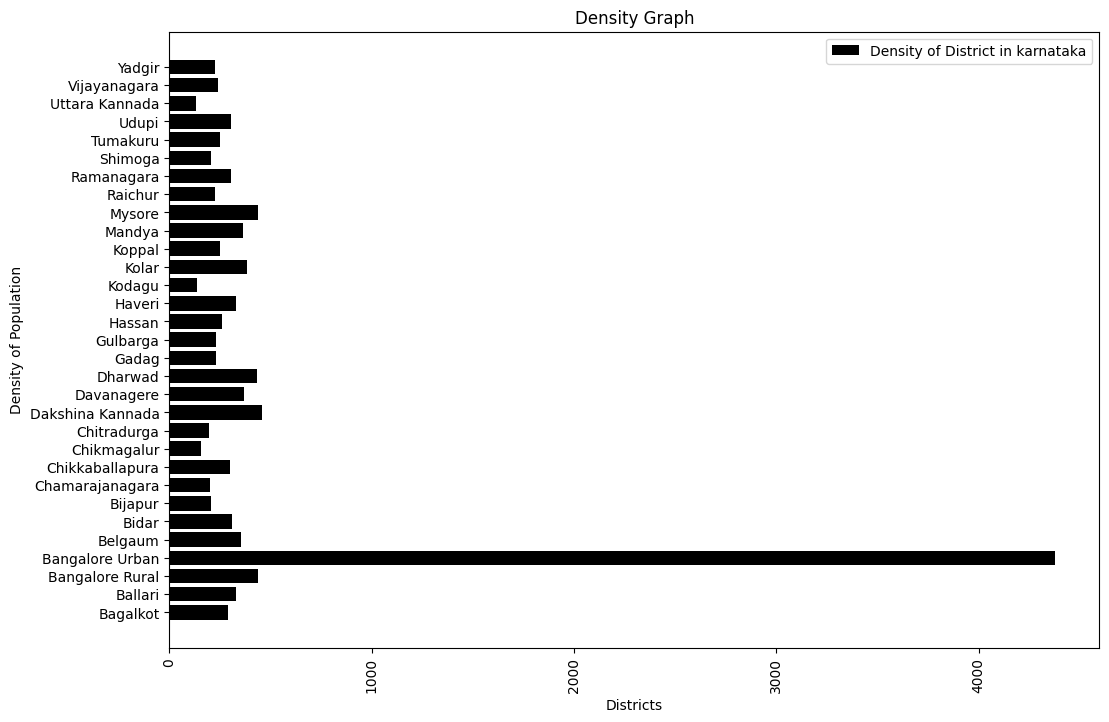

In [ ]:
state = 'Karnataka'
density = dd.groupby(['State','District'])['Density'].sum().reset_index()

new_den = density[density["State"] == state]
plt.figure(figsize=(12,8))
plt.barh(new_den['District'],new_den['Density'],label='Density of District in karnataka',color='black')
plt.xlabel('Districts')
plt.ylabel('Density of Population')

plt.xticks(rotation =90)
plt.title("Density Graph")
plt.legend()
plt.show()

**Correlation of Demographic data and Transaction Volume**

In [ ]:

merged = pd.merge(dd,dt_u,left_on='Code',right_on='Code',how='left')
merged['Transaction_volume'] = merged['Transactions']*merged['Amount (INR)']
correlation = merged['Density'].corr(merged['Transaction_volume']).round(2)
print(correlation)

0.09


**Trend in Transaction Type**

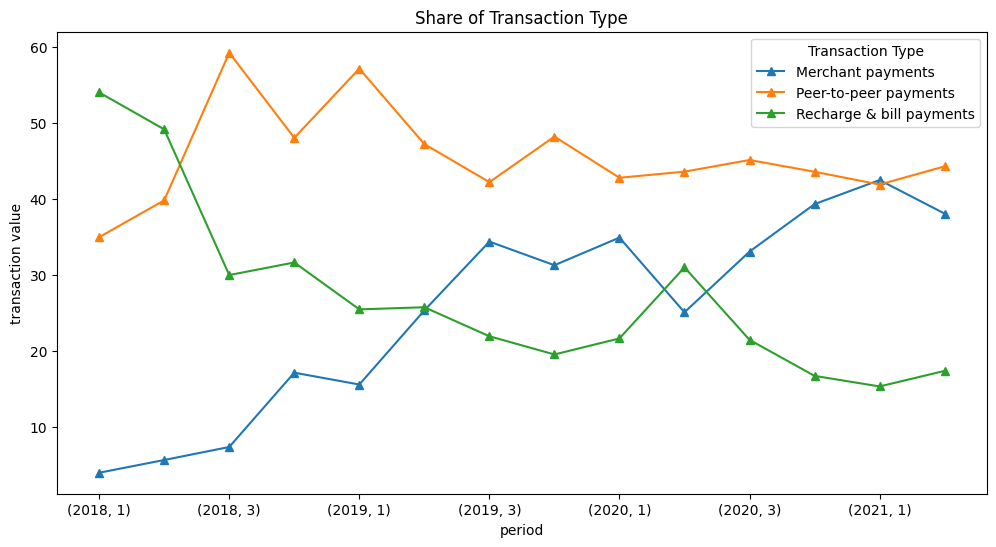

Transaction Type  Financial Services  Merchant payments    Others  \
Year Quarter                                                        
2018 1                      2.799184           3.993780  4.286052   
     2                      2.768156           5.664831  2.654273   
     3                      1.822033           7.376473  1.639190   
     4                      1.250544          17.141315  1.977025   
2019 1                      0.652665          15.584985  1.202571   
     2                      0.325049          25.321542  1.429581   
     3                      0.262125          34.366865  1.260718   
     4                      0.169595          31.262977  0.861613   
2020 1                      0.083681          34.894754  0.617793   
     2                      0.116116          25.077559  0.260903   
     3                      0.124540          33.054718  0.272564   
     4                      0.102553          39.295209  0.333058   
2021 1                      0.088942          42.455843  0.256002   
     2                      0.086197          38.048296  0.229912   

Transaction Type  Peer-to-peer payments  Recharge & bill payments  
Year Quarter                                                       
2018 1                        34.950586                 53.970398  
     2                        39.793123                 49.119617  
     3                        59.191662                 29.970642  
     4                        48.004924                 31.626192  
2019 1                        57.100638                 25.459140  
     2                        47.181607                 25.742223  
     3                        42.183283                 21.927009  
     4                        48.170030                 19.535785  
2020 1                        42.759178                 21.644594  
     2                        43.561125                 30.984297  
     3                        45.094198                 21.453980  
     4                        43.547846                 16.721334  
2021 1                        41.867241                 15.331971  
     2                        44.255294                 17.380301

In [ ]:
from matplotlib import markers
pivot = st_tx_s.pivot_table(index=['Year','Quarter'],columns='Transaction Type',values='Transactions',aggfunc='sum')
share_pct = pivot.div(pivot.sum(axis=1),axis=0)*100
share_pct[['Merchant payments','Peer-to-peer payments','Recharge & bill payments']].plot(figsize=(12,6),marker='^')
plt.xlabel('period')
plt.ylabel('transaction value')
plt.title("Share of Transaction Type")
plt.show()

share_pct


**Observation**

* There is increase in shar of Transaction Type of Merchant Payments from 3.99% to 38%.

* Meanwhile the Recharge & bill payments type has fallen from 54% to 17.38%

* Peer-to-peer transaction has grown at modrate pace from 35% to 44.25%

* There was sudden spike in peer-to-peer transaction type in 2018 (Quarter-3)to 2019 (Quarter-1)